In [16]:
## java runtime is no more available in colab. We'll have to install it manually.
!apt-get install openjdk-21-jdk-headless -qq > /dev/null

In [17]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [18]:
from pyspark.sql import SparkSession
spark=SparkSession.builder.appName('lung_cancer').getOrCreate()

In [19]:
# This PySpark code loads bank.csv into a DataFrame using the first row as column headers, automatically detects
# the column data types, and prints the resulting table structure.
df=spark.read.csv('survey lung cancer.csv',header=True,inferSchema=True)
df.printSchema()

root
 |-- GENDER: string (nullable = true)
 |-- AGE: integer (nullable = true)
 |-- SMOKING: integer (nullable = true)
 |-- YELLOW_FINGERS: integer (nullable = true)
 |-- ANXIETY: integer (nullable = true)
 |-- PEER_PRESSURE: integer (nullable = true)
 |-- CHRONIC DISEASE: integer (nullable = true)
 |-- FATIGUE : integer (nullable = true)
 |-- ALLERGY : integer (nullable = true)
 |-- WHEEZING: integer (nullable = true)
 |-- ALCOHOL CONSUMING: integer (nullable = true)
 |-- COUGHING: integer (nullable = true)
 |-- SHORTNESS OF BREATH: integer (nullable = true)
 |-- SWALLOWING DIFFICULTY: integer (nullable = true)
 |-- CHEST PAIN: integer (nullable = true)
 |-- LUNG_CANCER: string (nullable = true)



In [20]:
# df.show() displays the first 20 rows of your DataFrame in a formatted ASCII table in the console.
df.show()

+------+---+-------+--------------+-------+-------------+---------------+--------+--------+--------+-----------------+--------+-------------------+---------------------+----------+-----------+
|GENDER|AGE|SMOKING|YELLOW_FINGERS|ANXIETY|PEER_PRESSURE|CHRONIC DISEASE|FATIGUE |ALLERGY |WHEEZING|ALCOHOL CONSUMING|COUGHING|SHORTNESS OF BREATH|SWALLOWING DIFFICULTY|CHEST PAIN|LUNG_CANCER|
+------+---+-------+--------------+-------+-------------+---------------+--------+--------+--------+-----------------+--------+-------------------+---------------------+----------+-----------+
|     M| 69|      1|             2|      2|            1|              1|       2|       1|       2|                2|       2|                  2|                    2|         2|        YES|
|     M| 74|      2|             1|      1|            1|              2|       2|       2|       1|                1|       1|                  2|                    2|         2|        YES|
|     F| 59|      1|             1|

In [21]:
df.show(5)

+------+---+-------+--------------+-------+-------------+---------------+--------+--------+--------+-----------------+--------+-------------------+---------------------+----------+-----------+
|GENDER|AGE|SMOKING|YELLOW_FINGERS|ANXIETY|PEER_PRESSURE|CHRONIC DISEASE|FATIGUE |ALLERGY |WHEEZING|ALCOHOL CONSUMING|COUGHING|SHORTNESS OF BREATH|SWALLOWING DIFFICULTY|CHEST PAIN|LUNG_CANCER|
+------+---+-------+--------------+-------+-------------+---------------+--------+--------+--------+-----------------+--------+-------------------+---------------------+----------+-----------+
|     M| 69|      1|             2|      2|            1|              1|       2|       1|       2|                2|       2|                  2|                    2|         2|        YES|
|     M| 74|      2|             1|      1|            1|              2|       2|       2|       1|                1|       1|                  2|                    2|         2|        YES|
|     F| 59|      1|             1|

In [22]:
# df.count() returns the total number of rows in the DataFrame as an integer.
df.count()

309

In [23]:
# type(df) returns <class 'pyspark.sql.dataframe.DataFrame'>, confirming that df is a PySpark DataFrame object.
type(df)

pyspark.sql.classic.dataframe.DataFrame

In [24]:
# df.dtypes returns a Python list of (column_name, data_type) tuples representing the schema of the DataFrame.
df.dtypes

[('GENDER', 'string'),
 ('AGE', 'int'),
 ('SMOKING', 'int'),
 ('YELLOW_FINGERS', 'int'),
 ('ANXIETY', 'int'),
 ('PEER_PRESSURE', 'int'),
 ('CHRONIC DISEASE', 'int'),
 ('FATIGUE ', 'int'),
 ('ALLERGY ', 'int'),
 ('WHEEZING', 'int'),
 ('ALCOHOL CONSUMING', 'int'),
 ('COUGHING', 'int'),
 ('SHORTNESS OF BREATH', 'int'),
 ('SWALLOWING DIFFICULTY', 'int'),
 ('CHEST PAIN', 'int'),
 ('LUNG_CANCER', 'string')]

In [25]:
# This loop iterates through your DataFrame's columns and prints
# the names of all integer (int) columns on a single space-separated line.
for i in df.dtypes:
  if i[1]=="int":
    print(i[0],end=" ")

AGE SMOKING YELLOW_FINGERS ANXIETY PEER_PRESSURE CHRONIC DISEASE FATIGUE  ALLERGY  WHEEZING ALCOHOL CONSUMING COUGHING SHORTNESS OF BREATH SWALLOWING DIFFICULTY CHEST PAIN 

In [51]:
for i in df.dtypes:
  if i[1]!="int":
    print(i[0],end=" ")

label features 

In [52]:
num_col=[i[0] for i in df.dtypes if i[1]=="int"]
num_col

[]

In [48]:
cat_col=[i[0] for i in df.dtypes if i[1]!="int"]
cat_col

['label', 'features']

In [53]:
df.select(num_col).describe().show()

+-------+
|summary|
+-------+
|  count|
|   mean|
| stddev|
|    min|
|    max|
+-------+



In [50]:
df.select(cat_col).describe().show()

+-------+------------------+
|summary|             label|
+-------+------------------+
|  count|               309|
|   mean|0.1262135922330097|
| stddev|0.3326285997912192|
|    min|               0.0|
|    max|               1.0|
+-------+------------------+



In [32]:
from pyspark.ml.feature import VectorAssembler,StringIndexer,OneHotEncoder
stages=[]
for i in cat_col:
  string=StringIndexer(inputCol=i,outputCol=i+'Index')#An encoder defaults frequency encoding
  encoder=OneHotEncoder(inputCols=[string.getOutputCol()],outputCols=[i+"classVec"]) #Converting encoder column to OneHotEncoder
  stages+=[string,encoder]


In [33]:
stages

[StringIndexer_317f2550bc76,
 OneHotEncoder_80657ab632db,
 StringIndexer_e155aa360d1b,
 OneHotEncoder_015c807f0292]

In [34]:
target=StringIndexer(inputCol='LUNG_CANCER',outputCol='label') #Encoding Target Column
stages+=[target]


In [35]:
stages

[StringIndexer_317f2550bc76,
 OneHotEncoder_80657ab632db,
 StringIndexer_e155aa360d1b,
 OneHotEncoder_015c807f0292,
 StringIndexer_8457402ff872]

In [36]:
assembler=[c+"classVec" for c in cat_col]+num_col

In [37]:
assembler

['GENDERclassVec',
 'LUNG_CANCERclassVec',
 'AGE',
 'SMOKING',
 'YELLOW_FINGERS',
 'ANXIETY',
 'PEER_PRESSURE',
 'CHRONIC DISEASE',
 'FATIGUE ',
 'ALLERGY ',
 'WHEEZING',
 'ALCOHOL CONSUMING',
 'COUGHING',
 'SHORTNESS OF BREATH',
 'SWALLOWING DIFFICULTY',
 'CHEST PAIN']

In [38]:
vector_assembler=VectorAssembler(inputCols=assembler,outputCol="features")
stages+=[vector_assembler]

In [39]:
# 4. Fit and transform the Pipeline
# This code compiles your stages list into a PySpark ML Pipeline, fits all preprocessing
# and modeling steps on df, and overwrites df with the transformed output.
from pyspark.ml import Pipeline
pipeline = Pipeline(stages=stages)
pipelinemodel = pipeline.fit(df)
df= pipelinemodel.transform(df)

In [40]:
df.show(5)

+------+---+-------+--------------+-------+-------------+---------------+--------+--------+--------+-----------------+--------+-------------------+---------------------+----------+-----------+-----------+--------------+----------------+-------------------+-----+--------------------+
|GENDER|AGE|SMOKING|YELLOW_FINGERS|ANXIETY|PEER_PRESSURE|CHRONIC DISEASE|FATIGUE |ALLERGY |WHEEZING|ALCOHOL CONSUMING|COUGHING|SHORTNESS OF BREATH|SWALLOWING DIFFICULTY|CHEST PAIN|LUNG_CANCER|GENDERIndex|GENDERclassVec|LUNG_CANCERIndex|LUNG_CANCERclassVec|label|            features|
+------+---+-------+--------------+-------+-------------+---------------+--------+--------+--------+-----------------+--------+-------------------+---------------------+----------+-----------+-----------+--------------+----------------+-------------------+-----+--------------------+
|     M| 69|      1|             2|      2|            1|              1|       2|       1|       2|                2|       2|                  2| 

In [41]:
# This code strips away all original and intermediate columns from df,
# keeping only label and features, and previews the first 3 rows.
select_col=['label','features']
df=df.select(select_col)
df.show(3)

+-----+--------------------+
|label|            features|
+-----+--------------------+
|  0.0|[1.0,1.0,69.0,1.0...|
|  0.0|[1.0,1.0,74.0,2.0...|
|  1.0|[0.0,0.0,59.0,1.0...|
+-----+--------------------+
only showing top 3 rows


In [42]:
# This code randomly splits df into 70% training data and 30% testing data,
# then prints the exact row counts for each split.
train,test=df.randomSplit([0.7,0.3])
print("Train Data Count: ",str(train.count()))
print("Test Data Count: ",str(test.count()))

Train Data Count:  216
Test Data Count:  93


In [43]:
# This code initializes a Logistic Regression classifier capped at 10 iterations and
# trains it on your train DataFrame, producing a fitted lrModel.
from pyspark.ml.classification import LogisticRegression
lr=LogisticRegression(featuresCol='features',labelCol="label",maxIter=10)
lrModel=lr.fit(train)

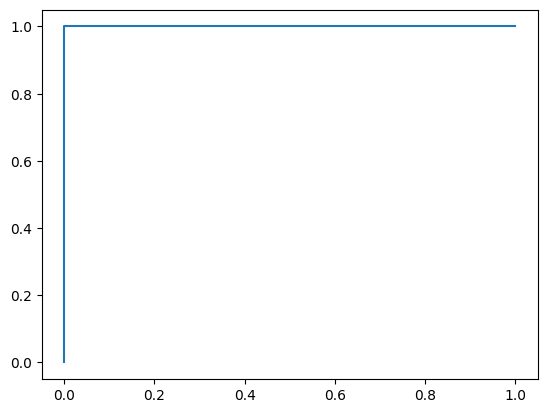

TrainingAUC:  1.0


In [44]:
import matplotlib.pyplot as plt
trainsummary=lrModel.summary
roc=trainsummary.roc.toPandas()
plt.plot(roc['FPR'],roc['TPR'])
plt.show()
print("TrainingAUC: ",trainsummary.areaUnderROC)

In [45]:
predictions=lrModel.transform(test)
predictions.show()

+-----+--------------------+--------------------+--------------------+----------+
|label|            features|       rawPrediction|         probability|prediction|
+-----+--------------------+--------------------+--------------------+----------+
|  0.0|[0.0,1.0,51.0,2.0...|[7.75666706265930...|[0.99957230269823...|       0.0|
|  0.0|[0.0,1.0,54.0,2.0...|[9.38150674956405...|[0.99991573896466...|       0.0|
|  0.0|[0.0,1.0,54.0,2.0...|[8.51337972555667...|[0.99979927614887...|       0.0|
|  0.0|[0.0,1.0,54.0,2.0...|[9.13727687171398...|[0.99989243168736...|       0.0|
|  0.0|[0.0,1.0,55.0,2.0...|[9.25938326970769...|[0.99990479503643...|       0.0|
|  0.0|[0.0,1.0,55.0,2.0...|[7.80139964968781...|[0.99959100545028...|       0.0|
|  0.0|[0.0,1.0,56.0,1.0...|[8.43908615699250...|[0.99978379907650...|       0.0|
|  0.0|[0.0,1.0,56.0,1.0...|[8.49467608433915...|[0.99979548732785...|       0.0|
|  0.0|[0.0,1.0,56.0,2.0...|[9.29385618365963...|[0.99990802080677...|       0.0|
|  0.0|[0.0,1.0,

In [46]:
# This code initializes PySpark's binary classification evaluator using default column names
# and computes the Area Under the ROC Curve (AUC-ROC) for your predictions DataFrame.
from  pyspark.ml.evaluation import BinaryClassificationEvaluator
eval=BinaryClassificationEvaluator()
print("Test Area UNder Roc: ",eval.evaluate(predictions))

Test Area UNder Roc:  1.0


In [33]:
#This code initializes a Decision Tree classifier with a maximum depth of 3, trains it
# on your train dataset, generates predictions on test, and evaluates performance using
# the Area Under the ROC curve (AUC-ROC).
from pyspark.ml.classification import DecisionTreeClassifier
dr=DecisionTreeClassifier(featuresCol='features',labelCol="label",maxDepth=3)
drModel=dr.fit(train)
predictions_1=drModel.transform(test)
print("Test Area UNder Roc: ",eval.evaluate(predictions_1))

Test Area UNder Roc:  1.0


In [34]:
# This code trains a Random Forest classifier using Spark's default hyperparameters,
# previews the first two rows of test predictions, and explicitly evaluates the model
# using the Area Under the ROC curve.
from pyspark.ml.classification import RandomForestClassifier
rf=RandomForestClassifier(featuresCol='features',labelCol="label")
rfModel=rf.fit(train)
predictions_rf=rfModel.transform(test)
predictions_rf.show(2)
print("Test Area UNder Roc: ",eval.evaluate(predictions_rf,{eval.metricName:"areaUnderROC"}))

+-----+--------------------+--------------------+--------------------+----------+
|label|            features|       rawPrediction|         probability|prediction|
+-----+--------------------+--------------------+--------------------+----------+
|  0.0|[0.0,1.0,44.0,2.0...|          [19.0,1.0]|         [0.95,0.05]|       0.0|
|  0.0|[0.0,1.0,47.0,2.0...|[19.2045454545454...|[0.96022727272727...|       0.0|
+-----+--------------------+--------------------+--------------------+----------+
only showing top 2 rows
Test Area UNder Roc:  1.0


In [35]:
#These imports bring in the PySpark ML tools required to rescale your features into
# a non-negative [0, 1] range, train a Naive Bayes classifier,
# and evaluate binary classification results
from pyspark.ml.feature import MinMaxScaler
from pyspark.ml.classification import NaiveBayes
from pyspark.ml.evaluation import BinaryClassificationEvaluator

# Step 1: Scaling
scaler = MinMaxScaler(
    inputCol="features",
    outputCol="scaledFeature"
)

scalerModel1 = scaler.fit(train)

train = scalerModel1.transform(train)
test = scalerModel1.transform(test)

# Step 2: Naive Bayes Model
nb = NaiveBayes(
    featuresCol="scaledFeature",
    labelCol="label"
)

nbModel = nb.fit(train)

# Step 3: Predictions
predictions_nb = nbModel.transform(test)

predictions_nb.show(2)

# Step 4: Evaluation
evaluator = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

#print("Test Area Under ROC:", evaluator.evaluate(predictions_nb))

+-----+--------------------+--------------------+--------------------+--------------------+----------+
|label|            features|       scaledFeature|       rawPrediction|         probability|prediction|
+-----+--------------------+--------------------+--------------------+--------------------+----------+
|  0.0|[0.0,1.0,44.0,2.0...|[0.0,1.0,0.122448...|[-25.154899905496...|[0.96944815837034...|       0.0|
|  0.0|[0.0,1.0,47.0,2.0...|[0.0,1.0,0.183673...|[-27.879900250744...|[0.99147459549678...|       0.0|
+-----+--------------------+--------------------+--------------------+--------------------+----------+
only showing top 2 rows


In [6]:
# Spark Setup
from pyspark.sql import SparkSession
spark=SparkSession.builder.appName("PySpark_Basics").master("local[*]").getOrCreate()

In [7]:

#You have Pandas it is possible to process large csv
#Daily receiving 15TB its not possible to load using Pandas
#Using Spark
sales_data=[
    (1,101,"Laptop",2,50000),
    (2,102,"Keyboard",1,1000),
    (3,103,"Mouse",3,5000),
]

In [8]:
sales=spark.createDataFrame(sales_data,["order_id","Customer_id","Product","Qty","Price"])

In [9]:
type(sales)

pyspark.sql.classic.dataframe.DataFrame

In [10]:
#  displays the first 2 rows of the sales DataFrame in a formatted ASCII table in the console.
sales.show(2)

+--------+-----------+--------+---+-----+
|order_id|Customer_id| Product|Qty|Price|
+--------+-----------+--------+---+-----+
|       1|        101|  Laptop|  2|50000|
|       2|        102|Keyboard|  1| 1000|
+--------+-----------+--------+---+-----+
only showing top 2 rows


In [11]:
# This code adds a new column named total_amount to your sales DataFrame by
# multiplying the Qty and Price columns row by row.
sales=sales.withColumn("total_amount",sales["Qty"]*sales["Price"])

In [12]:
sales.show(3)

+--------+-----------+--------+---+-----+------------+
|order_id|Customer_id| Product|Qty|Price|total_amount|
+--------+-----------+--------+---+-----+------------+
|       1|        101|  Laptop|  2|50000|      100000|
|       2|        102|Keyboard|  1| 1000|        1000|
|       3|        103|   Mouse|  3| 5000|       15000|
+--------+-----------+--------+---+-----+------------+



In [13]:
from pyspark.sql.functions import sum
# Ensure the total_amount column is created on the sales DataFrame before grouping
sales = sales.withColumn("total_amount", sales["Qty"] * sales["Price"])
result = sales.groupBy("Product").agg(sum("total_amount"))

In [14]:
result.show(2)

+-------+-----------------+
|Product|sum(total_amount)|
+-------+-----------------+
| Laptop|           100000|
|  Mouse|            15000|
+-------+-----------------+
only showing top 2 rows
